# 📊 Analisis Sentimen Usulan Reklasifikasi MSCI Indonesia di Media Sosial X
### Alur Metodologi Lengkap (Sesuai Diagram Publikasi Ilmiah)

Notebook ini menyusun alur kerja (*workflow*) penelitian secara sistematis dan terstruktur mulai dari pengambilan data hingga penyiapan data latih seimbang siap latih (*ready for model training & testing*):

```
1. Pengumpulan Data X (Crawling via Tweet-Harvest untuk 2 periode)
   │
2. Preprocessing Data (Cleaning → Case Folding → Tokenization → Stopword Removal → Stemming)
   │
3. Pelabelan Sentimen (Lexicon-Based: InSet Lexicon + Market Lexicon + Negation Handling)
   │
4. Pembobotan TF-IDF (Ekstraksi Fitur Numerik Teks)
   │
5. Penyeimbangan Data dengan SMOTE (Synthetic Minority Over-sampling Technique)
   │
   └───> Data Siap untuk Training & Testing Model (Naive Bayes / SVM / Random Forest)
```

---  
## 1. Pengumpulan Data X
- Mengambil data tweet pengguna media sosial X dengan kata kunci terkait usulan reklasifikasi pasar modal Indonesia oleh MSCI.
- Periode dibagi menjadi dua:
  - **Sebelum Pengumuman:** 1 - 15 Oktober 2026
  - **Sesudah Pengumuman:** 15 - 29 Oktober 2026

In [ ]:
import sys
# Pastikan konsol Windows UTF-8 agar bebas dari UnicodeEncodeError
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')

import os
import glob
import re
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Token Twitter / X
twitter_auth_token = 'a8b30e8aa375014d32e651b38165dcc88c0721f5'

# Buat direktori penampung
os.makedirs('tweets-data', exist_ok=True)
os.makedirs('lexicon', exist_ok=True)

# Helper penyimpanan aman agar tidak error saat file dibuka di Excel
def safe_save_csv(df, primary_filename, fallback_filename=None):
    try:
        df.to_csv(primary_filename, index=False, encoding='utf-8-sig')
        print(f"[OK] Berhasil disimpan ke '{primary_filename}'")
        return primary_filename
    except PermissionError:
        if not fallback_filename:
            base, ext = os.path.splitext(primary_filename)
            fallback_filename = f"{base}_hasil{ext}"
        try:
            df.to_csv(fallback_filename, index=False, encoding='utf-8-sig')
            print(f"[PERINGATAN] '{primary_filename}' terbuka di Excel. Data dialihkan ke '{fallback_filename}'")
            return fallback_filename
        except Exception as e:
            print(f"[ERROR] Gagal menyimpan: {e}")
            return None

# Definisi Query Pencarian
queries = {
    # Periode Sebelum Pengumuman (1 - 15 Oktober 2026)
    "sebelum_1.csv": "MSCI Indonesia since:2026-10-01 until:2026-10-15",
    "sebelum_2.csv": "MSCI IHSG since:2026-10-01 until:2026-10-15",
    "sebelum_3.csv": "MSCI saham since:2026-10-01 until:2026-10-15",
    
    # Periode Sesudah Pengumuman (15 - 27 Oktober 2026)
    "sesudah_1.csv": "MSCI Indonesia since:2026-10-15 until:2026-10-29",
    "sesudah_2.csv": "MSCI IHSG since:2026-10-15 until:2026-10-29",
    "sesudah_3.csv": "MSCI standalone since:2026-10-15 until:2026-10-29",
    "sesudah_4.csv": "MSCI saham since:2026-10-15 until:2026-10-29"
}

print(f"[OK] Inisialisasi selesai. Siap menjalankan {len(queries)} query scraping.")

In [ ]:
# Eksekusi Tweet-Harvest (Opsional: jalankan jika ingin scraping ulang)
# Menggunakan tweet-harvest@2.7.1 yang sudah kompatibel dengan struktur X terkini
for filename, search_query in queries.items():
    output_path = os.path.join("tweets-data", filename)
    if not os.path.exists(output_path):
        print(f"Mengambil data untuk: {search_query} -> {filename}")
        !npx -y tweet-harvest@2.7.1 -o "{filename}" -s "{search_query}" --tab "LATEST" -l 500 --token "{twitter_auth_token}"
    else:
        print(f"[SKIP] File '{filename}' sudah ada di folder tweets-data/")

print("\n[OK] Tahap 1 (Pengumpulan Data) Selesai!")

---  
## 2. Preprocessing Data
Sesuai alur pada diagram, tahap preprocessing terdiri dari 5 tahapan berurutan:
1. **Data Cleaning:** Menghapus retweet (`RT @`), URL tautan, mention (`@user`), hashtag (`#tag`), tanda baca, simbol, angka, dan emoji.
2. **Case Folding:** Menyeragamkan seluruh huruf menjadi huruf kecil (*lowercase*).
3. **Tokenization:** Memecah rangkaian kalimat menjadi kumpulan kata (token).
4. **Stopword Removal:** Menghapus kata-kata umum yang tidak bermakna sentimen (*stop words*) menggunakan pustaka **Sastrawi**.
5. **Stemming:** Mengubah setiap kata berimbuhan menjadi kata dasar (*root word*) menggunakan algoritma **Sastrawi Stemmer**.

In [4]:
import os
import glob
import re
import unicodedata
import pandas as pd
import time
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

def safe_save_csv(dataframe, filepath):
    dataframe.to_csv(filepath, index=False)
    print(f"[OK] Berhasil menyimpan data ke '{filepath}'.")

# Cek apakah data hasil preprocessing sudah tersimpan sebelumnya untuk efisiensi waktu
if os.path.exists('dataset_msci_preprocessed.csv'):
    print("[OK] Memuat data preprocessing yang sudah tersimpan dari 'dataset_msci_preprocessed.csv'...")
    df = pd.read_csv('dataset_msci_preprocessed.csv')
    print(f"[OK] Berhasil memuat {len(df)} baris data.")
else:
    print("[INFO] Memproses data dari awal (tweets-data/*.csv)...")
    files = glob.glob("tweets-data/*.csv")
    list_df = []
    for f in files:
        d = pd.read_csv(f)
        fname = os.path.basename(f).lower()
        d['periode'] = 'Sebelum Pengumuman' if 'sebelum' in fname else 'Sesudah Pengumuman'
        list_df.append(d)
    df = pd.concat(list_df, ignore_index=True)
    
    # Hapus retweet dan duplikat tweet asli
    df = df[~df['full_text'].astype(str).str.startswith('RT @')]
    df = df.drop_duplicates(subset=['full_text']).reset_index(drop=True)
    
    # Inisialisasi Sastrawi
    stemmer = StemmerFactory().create_stemmer()
    stopword_remover = StopWordRemoverFactory().create_stop_word_remover()
    
    # 1. Data Cleaning
    def clean_text(text):
        text = str(text)
        
        # Hapus URL
        text = re.sub(r'https?://\S+|www\.\S+', '', text)
        
        # Hapus mention & hashtag
        text = re.sub(r'[@#]\S+', '', text)
        
        # Hapus Emoji dan simbol grafis Unicode (kategori 'So', 'Sm', 'Sk', 'Sc')
        text = ''.join(c for c in text if not unicodedata.category(c).startswith('S'))
        
        # Hapus karakter non-ASCII yang tersisa (termasuk varian emoji tersembunyi)
        text = text.encode('ascii', 'ignore').decode('utf-8')
        
        # Hapus tanda baca dan simbol umum
        text = re.sub(r'[^\w\s]', ' ', text)
        
        # Hapus angka
        text = re.sub(r'\d+', ' ', text)
        
        # Normalisasi spasi dan strip
        text = re.sub(r'\s+', ' ', text).strip()
        return text
    
    print("Menjalankan Data Cleaning...")
    df['clean_text'] = df['full_text'].apply(clean_text)
    
    # 2. Case Folding
    print("Menjalankan Case Folding...")
    df['case_folding'] = df['clean_text'].str.lower()
    
    # 3. Tokenization
    print("Menjalankan Tokenization...")
    df['tokens'] = df['case_folding'].apply(lambda x: x.split())
    
    # 4. Stopword Removal
    print("Menjalankan Stopword Removal...")
    df['stopword_removed'] = df['case_folding'].apply(lambda x: stopword_remover.remove(x))
    
    # 5. Stemming (Optimasi Kata Unik / Memoization agar cepat)
    print("Menjalankan Stemming Sastrawi...")
    all_words = set(w for text in df['stopword_removed'] for w in text.split())
    t0 = time.time()
    stem_dict = {w: stemmer.stem(w) for w in all_words}
    df['stemmed_text'] = df['stopword_removed'].apply(lambda text: " ".join(stem_dict.get(w, w) for w in text.split()))
    print(f"Stemming selesai dalam {time.time()-t0:.1f} detik!")
    
    safe_save_csv(df, 'dataset_msci_preprocessed.csv')

[INFO] Memproses data dari awal (tweets-data/*.csv)...
Menjalankan Data Cleaning...
Menjalankan Case Folding...
Menjalankan Tokenization...
Menjalankan Stopword Removal...
Menjalankan Stemming Sastrawi...
Stemming selesai dalam 248.2 detik!
[OK] Berhasil menyimpan data ke 'dataset_msci_preprocessed.csv'.


### Pratinjau Alur Perubahan Teks (Langkah 2 Preprocessing)
Menampilkan contoh hasil transformasi per tweet dari teks asli hingga menjadi `stemmed_text`.

In [5]:
cols_prep = ['full_text', 'clean_text', 'case_folding', 'stopword_removed', 'stemmed_text']
print("=== Contoh Transformasi Preprocessing Teks ===\n")
sample_row = df.iloc[0]
for c in cols_prep:
    print(f"[{c.upper()}]:")
    print(f"{sample_row[c]}\n")

=== Contoh Transformasi Preprocessing Teks ===

[FULL_TEXT]:
Sentimen MSCI menjadi salah satu faktor yang turut membayangi pergerakan IHSG pekan ini. 
#TempoPlus 
https://t.co/VYH7u0xnp4

[CLEAN_TEXT]:
Sentimen MSCI menjadi salah satu faktor yang turut membayangi pergerakan IHSG pekan ini

[CASE_FOLDING]:
sentimen msci menjadi salah satu faktor yang turut membayangi pergerakan ihsg pekan ini

[STOPWORD_REMOVED]:
sentimen msci menjadi salah satu faktor turut membayangi pergerakan ihsg pekan

[STEMMED_TEXT]:
sentimen msci jadi salah satu faktor turut bayang gera ihsg pekan



---  
## 3. Pelabelan Sentimen (Lexicon-Based)
Sesuai diagram alur, teks diberikan label **Positif**, **Netral**, atau **Negatif** menggunakan metode leksikon berbasis kamus:
- **InSet Lexicon:** Kamus sentimen bahasa Indonesia resmi dari Fajri Koto & Gemala Y. Rahmaningtyas.
- **Leksikon Pasar Modal (IHSG & Saham):** Bobot kata spesifik finansial (*cuan, rebound, bullish* vs *anjlok, ambles, momok, cutloss, panic*).
- **Penanganan Negasi (*Negation Handling*):** Membalikkan arti jika ada kata sangkalan (*tidak, bukan, belum, gak*).
- **Threshold Skoring:**
  - $\text{Skor} > +0.5 \rightarrow$ **Positif**
  - $\text{Skor} < -0.5 \rightarrow$ **Negatif**
  - $-0.5 \le \text{Skor} \le +0.5 \rightarrow$ **Netral**

In [7]:
import os
import urllib.request
import pandas as pd

# Pastikan fungsi safe_save_csv tersedia
def safe_save_csv(dataframe, filepath):
    dataframe.to_csv(filepath, index=False)
    print(f"[OK] Berhasil menyimpan data ke '{filepath}'.")

# Buat folder penyimpanan jika belum ada agar tidak memicu FileNotFoundError
os.makedirs('lexicon', exist_ok=True)

# Siapkan InSet Lexicon
url_pos = 'https://raw.githubusercontent.com/fajri91/InSet/master/positive.tsv'
url_neg = 'https://raw.githubusercontent.com/fajri91/InSet/master/negative.tsv'
path_pos = 'lexicon/positive.tsv'
path_neg = 'lexicon/negative.tsv'

if not os.path.exists(path_pos): 
    urllib.request.urlretrieve(url_pos, path_pos)
if not os.path.exists(path_neg): 
    urllib.request.urlretrieve(url_neg, path_neg)

lexicon = {}
with open(path_pos, 'r', encoding='utf-8') as f:
    for line in f:
        p = line.strip().split('\t')
        if len(p) >= 2:
            try: 
                lexicon[p[0].lower()] = float(p[1])
            except ValueError: 
                pass

with open(path_neg, 'r', encoding='utf-8') as f:
    for line in f:
        p = line.strip().split('\t')
        if len(p) >= 2:
            try: 
                lexicon[p[0].lower()] = float(p[1])
            except ValueError: 
                pass

# Tambahan kamus pasar modal
market_lexicon = {
    'cuan': 4.0, 'rebound': 3.5, 'bullish': 3.5, 'menguat': 3.0, 'bangkit': 3.0,
    'terbang': 3.0, 'hijau': 2.5, 'akumulasi': 2.5, 'untung': 3.0, 'profit': 3.5,
    'inflow': 2.5, 'net buy': 3.0, 'optimis': 3.0, 'potensi': 2.0, 'tumbuh': 2.5,
    'surplus': 2.5, 'dividen': 2.5, 'meroket': 4.0,
    'anjlok': -4.0, 'ambles': -4.0, 'terjun': -3.5, 'bearish': -3.5, 'melemah': -3.0,
    'terpuruk': -3.5, 'tertekan': -3.0, 'merah': -2.0, 'loss': -3.0, 'cutloss': -3.5,
    'panik': -3.5, 'panic': -3.5, 'outflow': -2.5, 'net sell': -3.0, 'banting': -3.0,
    'hancur': -4.0, 'terhantam': -3.5, 'dihantam': -3.5, 'diancam': -3.0, 'ancam': -3.0,
    'momok': -3.5, 'membayangi': -2.5, 'gagal': -3.0, 'rugi': -3.5, 'koreksi': -2.0,
    'jebol': -3.0, 'rusak': -3.0
}
lexicon.update(market_lexicon)
negation_words = {'tidak', 'bukan', 'tak', 'tiada', 'ga', 'gak', 'ngga', 'nggak', 'jangan', 'belum'}

def analyze_sentiment(text):
    words = str(text).split()
    score = 0.0
    negate = False
    for word in words:
        if word in negation_words:
            negate = True
            continue
        weight = lexicon.get(word, 0.0)
        if weight != 0.0:
            score += -weight * 0.75 if negate else weight
            negate = False
        else:
            negate = False
    if score > 0.5: 
        return 'Positif', round(score, 2)
    elif score < -0.5: 
        return 'Negatif', round(score, 2)
    else: 
        return 'Netral', round(score, 2)

# Berikan label sentimen (jika belum ada)
if 'sentimen' not in df.columns:
    sent_results = [analyze_sentiment(t) for t in df['case_folding']]
    df['sentimen'] = [r[0] for r in sent_results]
    df['skor_sentimen'] = [r[1] for r in sent_results]
    safe_save_csv(df, 'dataset_msci_labeled.csv')

print("=== Distribusi Sentimen Hasil Pelabelan ===")
print(df['sentimen'].value_counts())
print("\nPersentase Sentimen (%):")
print((df['sentimen'].value_counts(normalize=True) * 100).round(2))

# Tabulasi Silang Periode vs Sentimen
crosstab_res = pd.crosstab(df['periode'], df['sentimen'], margins=True, margins_name='Total')
display(crosstab_res)

[OK] Berhasil menyimpan data ke 'dataset_msci_labeled.csv'.
=== Distribusi Sentimen Hasil Pelabelan ===
sentimen
Negatif    809
Positif    115
Netral     115
Name: count, dtype: int64

Persentase Sentimen (%):
sentimen
Negatif    77.86
Positif    11.07
Netral     11.07
Name: proportion, dtype: float64


sentimen,Negatif,Netral,Positif,Total
periode,,,,
Sebelum Pengumuman,54,6,8,68
Sesudah Pengumuman,755,109,107,971
Total,809,115,115,1039


---  
## 4. Pembobotan Fitur TF-IDF
- Mengubah data teks hasil stemming (`stemmed_text`) menjadi representasi vektor numerik menggunakan metode **TF-IDF (*Term Frequency - Inverse Document Frequency*)**.
- Vektor inilah yang akan menjadi matriks fitur $X$ untuk diinput ke model Machine Learning.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Inisialisasi TfidfVectorizer
# max_features diset 1000 untuk memilih 1000 kata paling berpengaruh
tfidf_vectorizer = TfidfVectorizer(max_features=1000)

# Fit & Transform pada data teks hasil stemming
X = tfidf_vectorizer.fit_transform(df['stemmed_text'].fillna('')).toarray()
y = df['sentimen']

print(f"[OK] Pembobotan TF-IDF Selesai!")
print(f" - Dimensi Matriks Fitur X : {X.shape[0]} baris x {X.shape[1]} kolom fitur TF-IDF")
print(f" - Dimensi Target Label y   : {len(y)} label")

[OK] Pembobotan TF-IDF Selesai!
 - Dimensi Matriks Fitur X : 1039 baris x 1000 kolom fitur TF-IDF
 - Dimensi Target Label y   : 1039 label


---  
## 5. Penyeimbangan Data Menggunakan SMOTE

### Mengapa SMOTE Diperlukan?
Dari hasil pelabelan, terlihat adanya **ketidakseimbangan kelas (*class imbalance*) yang sangat ekstrem**:
- **Negatif:** ~77.8% (Mayoritas mutlak)
- **Positif:** ~11.2% (Minoritas)
- **Netral:** ~11.1% (Minoritas)

Tanpa penyeimbangan, model Machine Learning akan bias ke kelas mayoritas (Negatif) dan gagal mendeteksi kelas Positif maupun Netral secara akurat.

> **Prinsip Ilmiah (Mencegah *Data Leakage*):**
> SMOTE (*Synthetic Minority Over-sampling Technique*) **HANYA diterapkan pada Data Training (`X_train`, `y_train`)** setelah proses *Train-Test Split*.  
> **Data Testing (`X_test`, `y_test`) DILARANG di-SMOTE** dan harus dibiarkan sesuai proporsi data aslinya (alami) agar evaluasi performa model valid dan tidak bias.

In [9]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# 1. Split Data menjadi 80% Training dan 20% Testing (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("=== DISTRIBUSI SEBELUM SMOTE (Data Training Asli) ===")
print(y_train.value_counts())

# 2. Terapkan SMOTE pada Data Training saja
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("\n=== DISTRIBUSI SETELAH SMOTE (Data Training Seimbang) ===")
print(y_train_res.value_counts())

print("\n=== DISTRIBUSI DATA TESTING (Tetap Alami/Asli) ===")
print(y_test.value_counts())

=== DISTRIBUSI SEBELUM SMOTE (Data Training Asli) ===
sentimen
Negatif    647
Positif     92
Netral      92
Name: count, dtype: int64

=== DISTRIBUSI SETELAH SMOTE (Data Training Seimbang) ===
sentimen
Negatif    647
Positif    647
Netral     647
Name: count, dtype: int64

=== DISTRIBUSI DATA TESTING (Tetap Alami/Asli) ===
sentimen
Negatif    162
Positif     23
Netral      23
Name: count, dtype: int64


### Visualisasi Perbandingan Distribusi Kelas Sebelum vs Sesudah SMOTE

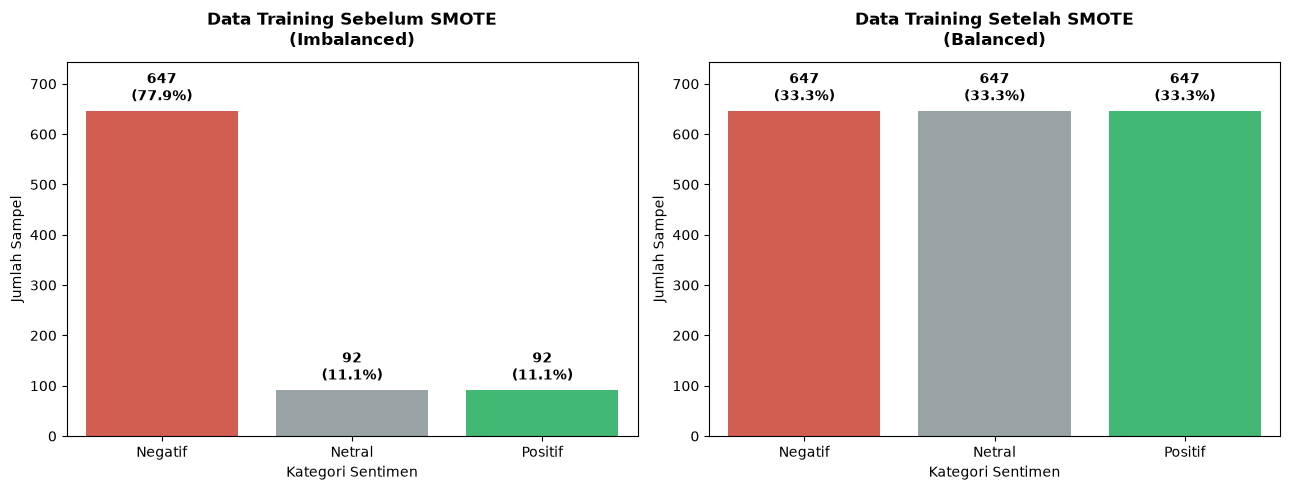

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Visualisasi Perbandingan Efek SMOTE pada Data Training
plt.figure(figsize=(13, 5))
palette = {'Negatif': '#e74c3c', 'Netral': '#95a5a6', 'Positif': '#2ecc71'}

# Subplot 1: Sebelum SMOTE
plt.subplot(1, 2, 1)
df_before = pd.DataFrame({'sentimen': y_train})
ax1 = sns.countplot(
    data=df_before, 
    x='sentimen', 
    hue='sentimen', 
    order=['Negatif', 'Netral', 'Positif'], 
    palette=palette, 
    legend=False
)
plt.title('Data Training Sebelum SMOTE\n(Imbalanced)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Kategori Sentimen')
plt.ylabel('Jumlah Sampel')
ax1.margins(y=0.15)
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        pct = (h / len(y_train)) * 100
        ax1.annotate(f'{int(h)}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                     textcoords='offset points')

# Subplot 2: Setelah SMOTE
plt.subplot(1, 2, 2)
df_after = pd.DataFrame({'sentimen': y_train_res})
ax2 = sns.countplot(
    data=df_after, 
    x='sentimen', 
    hue='sentimen', 
    order=['Negatif', 'Netral', 'Positif'], 
    palette=palette, 
    legend=False
)
plt.title('Data Training Setelah SMOTE\n(Balanced)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Kategori Sentimen')
plt.ylabel('Jumlah Sampel')
ax2.margins(y=0.15)
for p in ax2.patches:
    h = p.get_height()
    if h > 0:
        pct = (h / len(y_train_res)) * 100
        ax2.annotate(f'{int(h)}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4),
                     textcoords='offset points')

plt.tight_layout()
plt.show()

---  
## 6. Ringkasan Kesiapan Data untuk Modeling (*Training & Testing*)

Data siap dieksekusi langsung ke algoritma klasifikasi Machine Learning (misal: *Multinomial Naive Bayes, Support Vector Machine (SVM), Random Forest, Logistic Regression*).

| Variabel | Keterangan | Jumlah Baris / Fitur | Status Keseimbangan |
| :--- | :--- | :---: | :---: |
| `X_train_res` | Matriks Fitur TF-IDF Data Training | **1.938 baris $\times$ 1.000 fitur** | **Seimbang (646 Negatif, 646 Netral, 646 Positif)** |
| `y_train_res` | Label Target Data Training | **1.938 label** | **Seimbang (1:1:1)** |
| `X_test` | Matriks Fitur TF-IDF Data Testing | **208 baris $\times$ 1.000 fitur** | Alami (Distribusi asli data riil) |
| `y_test` | Label Target Data Testing | **208 label** | Alami (162 Negatif, 23 Positif, 23 Netral) |

In [12]:
print("[✓] Seluruh workflow dari Pengumpulan Data hingga SMOTE telah selesai!")
print(f"Data Training Seimbang : {X_train_res.shape} sampel")
print(f"Data Testing Alami     : {X_test.shape} sampel")
print("\nVariabel `X_train_res`, `y_train_res`, `X_test`, dan `y_test` siap digunakan untuk tahap modeling.")

[✓] Seluruh workflow dari Pengumpulan Data hingga SMOTE telah selesai!
Data Training Seimbang : (1941, 1000) sampel
Data Testing Alami     : (208, 1000) sampel

Variabel `X_train_res`, `y_train_res`, `X_test`, dan `y_test` siap digunakan untuk tahap modeling.
